# Phase 16 — Fusion Model: DualBranchGAT + TCI Baseline

## Why this notebook exists

Phase 15 found that DualBranchGAT and the best TCI baseline
(`LR_worse_foot_tci`) make **complementary** errors:

- `GAT_ONLY_CORRECT` subjects (DualBranchGAT right, baseline wrong) are
  **94.7% DM** — DualBranchGAT specifically catches DM cases the baseline
  misses.
- `BASELINE_ONLY_CORRECT` subjects (baseline right, DualBranchGAT wrong) are
  **81.8% Control** — the baseline specifically catches Control cases
  DualBranchGAT misses.

This notebook tests whether **fusing** the two models' predicted
probabilities produces a model that beats both individually — and whether
that improvement is large enough to be statistically significant where the
individual comparisons in Phase 14 were not (DualBranchGAT vs.
`LR_worse_foot_tci`, DeLong p = 0.4575).

Three fusion approaches are tried:

- **A** — weighted average, with the weight selected fold-wise (no leakage).
- **B** — simple unweighted average (naive baseline for comparison).
- **C** — a stacked logistic-regression meta-classifier.

No models are retrained here. DualBranchGAT's and the TCI baseline's
out-of-fold probabilities are read directly from Phase 13/14's saved
results.


In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
)
import scipy.stats
import matplotlib.pyplot as plt
import json
from pathlib import Path

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

# Running tally of any integrity issues found in this notebook, printed in
# the final summary cell.
issues_found = []


## Section 1 — Setup: Load & Merge

Read DualBranchGAT's pooled out-of-fold predictions
(`results/cv_pooled_predictions.csv`, Phase 13) and the TCI baselines'
pooled out-of-fold predictions (`results/baseline_pooled_predictions.csv`,
Phase 14). Merge on `subject_id` into one 167-row working table
(`fusion_df`) with the columns this notebook needs: `subject_id`, `group`,
`true_label`, `fold`, `gat_prob` (= `mc_mean_prob`), `baseline_prob`
(= `LR_worse_foot_tci`). `LR_worse_foot_tci` was confirmed the best baseline
in Phase 14/15, so only that column is used here — `baseline_pooled_predictions.csv`
is loaded in full for completeness, but the other 3 baseline variants are
not used in this notebook.

The `fold` column in `cv_pooled_predictions.csv` is the single source of
truth for fold membership and is reused directly — folds are **not**
regenerated.


In [2]:
print("=== SECTION 1: Setup -- Load & Merge ===")

gat_df = pd.read_csv(RESULTS_DIR / "cv_pooled_predictions.csv")
baseline_df = pd.read_csv(RESULTS_DIR / "baseline_pooled_predictions.csv")

print(f"cv_pooled_predictions.csv shape:       {gat_df.shape}")
print(f"baseline_pooled_predictions.csv shape: {baseline_df.shape}")

# --- Merge -----------------------------------------------------------------
merged_df = gat_df.merge(
    baseline_df[["subject_id", "true_label", "LR_worse_foot_tci"]],
    on="subject_id",
    how="inner",
    suffixes=("_gat", "_baseline"),
)

fusion_df = pd.DataFrame({
    "subject_id": merged_df["subject_id"],
    "group": merged_df["group"],
    "true_label": merged_df["true_label_gat"],
    "fold": merged_df["fold"],
    "gat_prob": merged_df["mc_mean_prob"],
    "gat_pred_label_optimal": merged_df["pred_label_optimal"],
    "baseline_prob": merged_df["LR_worse_foot_tci"],
})

# --- Integrity checks --------------------------------------------------------
n_rows = len(fusion_df)
n_dupes = int(fusion_df["subject_id"].duplicated().sum())
label_mismatch = int((merged_df["true_label_gat"] != merged_df["true_label_baseline"]).sum())

pass_rows = n_rows == 167
pass_dupes = n_dupes == 0
pass_labels = label_mismatch == 0

print(f"\nRow count check (expect 167):        {'PASS' if pass_rows else 'FAIL'} ({n_rows} rows)")
print(f"No duplicate subject_id check:        {'PASS' if pass_dupes else 'FAIL'} ({n_dupes} duplicates)")
print(f"true_label agreement across files:    {'PASS' if pass_labels else 'FAIL'} ({label_mismatch} mismatches)")

overall_pass = pass_rows and pass_dupes and pass_labels
print(f"\nOVERALL SECTION 1: {'PASS' if overall_pass else 'FAIL'}")

if not overall_pass:
    issues_found.append(
        f"Section 1 merge integrity check failed (rows={n_rows}, dupes={n_dupes}, label_mismatch={label_mismatch})"
    )

assert pass_rows, f"Expected 167 merged rows, found {n_rows}"
assert pass_dupes, f"Found {n_dupes} duplicate subject_id values after merge"
assert pass_labels, f"Found {label_mismatch} true_label mismatches between the two source files"

fusion_df = fusion_df.reset_index(drop=True)
fusion_df.head()


=== SECTION 1: Setup -- Load & Merge ===
cv_pooled_predictions.csv shape:       (167, 6)
baseline_pooled_predictions.csv shape: (167, 7)

Row count check (expect 167):        PASS (167 rows)
No duplicate subject_id check:        PASS (0 duplicates)
true_label agreement across files:    PASS (0 mismatches)

OVERALL SECTION 1: PASS


,subject_id,group,true_label,fold,gat_prob,gat_pred_label_optimal,baseline_prob
0,CG007,Control,0,0,0.214824,0,0.127307
1,CG009,Control,0,0,0.191896,0,0.230497
2,CG010,Control,0,0,0.178642,0,0.198440
3,CG011,Control,0,0,0.237222,0,0.109968
4,CG024,Control,0,0,0.363434,1,0.141110


## Section 2 — Reimplement the DeLong Test

The paired DeLong test (Sun & Xu 2014 fast/midrank formulation) is
reimplemented here as a small, self-contained numpy function — it is **not**
imported from `13_baseline_comparison.ipynb`, so this notebook has no
cross-notebook dependency. It computes the AUCs of two correlated (same
subjects, same labels) classifiers, the covariance of the AUC estimators via
midranks, and a z-test on the AUC difference.


In [3]:
print("=== SECTION 2: Reimplement the DeLong Test ===")

def _compute_midrank(x):
    """Midranks of x, handling ties (Sun & Xu 2014)."""
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def _fast_delong(preds_sorted_transposed, label_1_count):
    """
    preds_sorted_transposed: (n_classifiers, n_examples), with the positive
    (label==1) examples first, negative examples after.
    Returns (aucs, covariance matrix) per Sun & Xu's fast DeLong algorithm.
    """
    m = label_1_count
    n = preds_sorted_transposed.shape[1] - m
    k = preds_sorted_transposed.shape[0]

    positive_examples = preds_sorted_transposed[:, :m]
    negative_examples = preds_sorted_transposed[:, m:]

    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = _compute_midrank(positive_examples[r, :])
        ty[r, :] = _compute_midrank(negative_examples[r, :])
        tz[r, :] = _compute_midrank(preds_sorted_transposed[r, :])

    aucs = tz[:, :m].sum(axis=1) / (m * n) - (m + 1.0) / (2.0 * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m
    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return aucs, delongcov


def delong_roc_test(true_label, prob_a, prob_b):
    """
    Paired DeLong test comparing two sets of predicted probabilities against
    the same true binary labels (same subjects, correctly paired).

    Returns a dict: auc_a, auc_b, auc_diff (a - b), z, p_value.
    """
    true_label = np.asarray(true_label)
    prob_a = np.asarray(prob_a, dtype=float)
    prob_b = np.asarray(prob_b, dtype=float)

    order = np.argsort(-true_label)  # positives (label==1) first
    label_1_count = int(np.sum(true_label))

    preds_sorted_transposed = np.vstack([prob_a, prob_b])[:, order]
    aucs, delongcov = _fast_delong(preds_sorted_transposed, label_1_count)

    auc_a, auc_b = float(aucs[0]), float(aucs[1])
    auc_diff = auc_a - auc_b
    var = delongcov[0, 0] + delongcov[1, 1] - 2 * delongcov[0, 1]
    se = float(np.sqrt(var)) if var > 0 else 0.0
    z = auc_diff / se if se > 0 else 0.0
    p_value = 2 * (1 - scipy.stats.norm.cdf(abs(z))) if se > 0 else 1.0

    return {
        "auc_a": auc_a,
        "auc_b": auc_b,
        "auc_diff": auc_diff,
        "z": float(z),
        "p_value": float(p_value),
    }

# Quick self-check: a classifier compared against itself should give AUC
# diff == 0 and p_value == 1.
_self_check = delong_roc_test(
    fusion_df["true_label"].values, fusion_df["gat_prob"].values, fusion_df["gat_prob"].values
)
print("Self-comparison sanity check (GAT vs itself):")
print(f"  auc_diff = {_self_check['auc_diff']:.6f} (expect 0.0)")
print(f"  p_value  = {_self_check['p_value']:.6f} (expect 1.0)")
_self_check_pass = abs(_self_check["auc_diff"]) < 1e-9 and abs(_self_check["p_value"] - 1.0) < 1e-6
print(f"  Self-check: {'PASS' if _self_check_pass else 'FAIL'}")
if not _self_check_pass:
    issues_found.append("DeLong self-comparison sanity check failed")


=== SECTION 2: Reimplement the DeLong Test ===
Self-comparison sanity check (GAT vs itself):
  auc_diff = 0.000000 (expect 0.0)
  p_value  = 1.000000 (expect 1.0)
  Self-check: PASS


## Section 3 — Fusion Approach A: Weighted Average (Fold-Wise Weight Selection)

For each of the 5 folds, the fusion weight `w` is chosen using **only** the
subjects in the other 4 folds (never this fold's own held-out subjects, to
avoid leakage): `fused_prob = w * gat_prob + (1-w) * baseline_prob` is swept
over `w` from 0.0 to 1.0 in steps of 0.05, and the `w` that maximizes
`roc_auc_score` on those other-fold subjects is kept. That fold's chosen `w`
is then applied to this fold's held-out subjects to produce their
out-of-fold fused probability. Pooling across all 5 folds gives one
167-subject out-of-fold `fusion_a_prob` column.


In [4]:
print("=== SECTION 3: Fusion Approach A -- Weighted Average (fold-wise weight selection) ===")

weights_grid = np.round(np.arange(0.0, 1.0001, 0.05), 2)
fold_weights_a = {}
fusion_a_prob = np.full(len(fusion_df), np.nan)

for fold in sorted(fusion_df["fold"].unique()):
    other_mask = (fusion_df["fold"] != fold).values
    this_mask = (fusion_df["fold"] == fold).values

    other_gat = fusion_df.loc[other_mask, "gat_prob"].values
    other_baseline = fusion_df.loc[other_mask, "baseline_prob"].values
    other_label = fusion_df.loc[other_mask, "true_label"].values

    best_w, best_auc = None, -np.inf
    for w in weights_grid:
        fused = w * other_gat + (1 - w) * other_baseline
        auc = roc_auc_score(other_label, fused)
        if auc > best_auc:
            best_auc, best_w = auc, w

    fold_weights_a[int(fold)] = float(best_w)

    this_gat = fusion_df.loc[this_mask, "gat_prob"].values
    this_baseline = fusion_df.loc[this_mask, "baseline_prob"].values
    fusion_a_prob[this_mask] = best_w * this_gat + (1 - best_w) * this_baseline

    print(f"Fold {int(fold)}: chosen w = {best_w:.2f}  (other-folds AUC at this w = {best_auc:.4f})")

fusion_df["fusion_a_prob"] = fusion_a_prob

n_missing_a = int(fusion_df["fusion_a_prob"].isna().sum())
print(f"\nFusion A missing-value check: {'PASS' if n_missing_a == 0 else 'FAIL'} ({n_missing_a} missing)")
if n_missing_a != 0:
    issues_found.append(f"Fusion A has {n_missing_a} missing out-of-fold values")
assert n_missing_a == 0, "Fusion A has missing out-of-fold values"


=== SECTION 3: Fusion Approach A -- Weighted Average (fold-wise weight selection) ===
Fold 0: chosen w = 0.70  (other-folds AUC at this w = 0.8680)
Fold 1: chosen w = 0.75  (other-folds AUC at this w = 0.9066)
Fold 2: chosen w = 0.75  (other-folds AUC at this w = 0.9056)
Fold 3: chosen w = 0.55  (other-folds AUC at this w = 0.8892)
Fold 4: chosen w = 0.55  (other-folds AUC at this w = 0.9028)

Fusion A missing-value check: PASS (0 missing)


## Section 4 — Fusion Approach B: Unweighted Average (Naive Baseline)

A simple `fused_prob = 0.5 * gat_prob + 0.5 * baseline_prob`, computed
directly with no fold-wise fitting required (there is nothing to fit — the
weight is fixed at 0.5 by construction). This serves as a naive baseline
against which Approach A's fold-wise weight selection and Approach C's
learned stacking can be judged.


In [5]:
print("=== SECTION 4: Fusion Approach B -- Unweighted Average ===")

fusion_df["fusion_b_prob"] = 0.5 * fusion_df["gat_prob"] + 0.5 * fusion_df["baseline_prob"]

print("fusion_b_prob computed directly for all 167 subjects (fused_prob = 0.5*gat_prob + 0.5*baseline_prob).")
print(fusion_df["fusion_b_prob"].describe())


=== SECTION 4: Fusion Approach B -- Unweighted Average ===
fusion_b_prob computed directly for all 167 subjects (fused_prob = 0.5*gat_prob + 0.5*baseline_prob).
count    167.000000
mean       0.637336
std        0.285333
min        0.144265
25%        0.348487
50%        0.696845
75%        0.899392
max        0.998677
Name: fusion_b_prob, dtype: float64


## Section 5 — Fusion Approach C: Stacked Logistic Regression Meta-Classifier

For each of the 5 folds, a `LogisticRegression(class_weight='balanced')` is
fit on the 2 features `[gat_prob, baseline_prob]` using only the other 4
folds' subjects, then used to predict probabilities for this fold's
held-out subjects — the same no-leakage, fold-wise pattern as Approach A,
but with a learned (rather than swept) combination rule. Pooling across all
5 folds gives one 167-subject out-of-fold `fusion_c_prob` column.

Each fold's fitted coefficients are printed — these are informative on
their own: do they confirm GAT receives more weight, consistent with Phase
15's finding that DualBranchGAT is the stronger individual model (higher
pooled AUC: 0.8778 vs. 0.8588 for `LR_worse_foot_tci`)?


In [6]:
print("=== SECTION 5: Fusion Approach C -- Stacked Logistic Regression Meta-Classifier ===")

fusion_c_prob = np.full(len(fusion_df), np.nan)
fold_coefs_c = []

for fold in sorted(fusion_df["fold"].unique()):
    other_mask = (fusion_df["fold"] != fold).values
    this_mask = (fusion_df["fold"] == fold).values

    X_train = fusion_df.loc[other_mask, ["gat_prob", "baseline_prob"]].values
    y_train = fusion_df.loc[other_mask, "true_label"].values
    X_test = fusion_df.loc[this_mask, ["gat_prob", "baseline_prob"]].values

    clf = LogisticRegression(class_weight="balanced")
    clf.fit(X_train, y_train)

    probs = clf.predict_proba(X_test)[:, 1]
    fusion_c_prob[this_mask] = probs

    coef_gat, coef_baseline = clf.coef_[0]
    intercept = clf.intercept_[0]
    fold_coefs_c.append((coef_gat, coef_baseline, intercept))

    print(
        f"Fold {int(fold)}: coef_gat_prob = {coef_gat:+.4f}, "
        f"coef_baseline_prob = {coef_baseline:+.4f}, intercept = {intercept:+.4f}"
    )

fusion_df["fusion_c_prob"] = fusion_c_prob

n_missing_c = int(fusion_df["fusion_c_prob"].isna().sum())
print(f"\nFusion C missing-value check: {'PASS' if n_missing_c == 0 else 'FAIL'} ({n_missing_c} missing)")
if n_missing_c != 0:
    issues_found.append(f"Fusion C has {n_missing_c} missing out-of-fold values")
assert n_missing_c == 0, "Fusion C has missing out-of-fold values"

mean_coef_gat = float(np.mean([c[0] for c in fold_coefs_c]))
mean_coef_baseline = float(np.mean([c[1] for c in fold_coefs_c]))
print(f"\nMean gat_prob coefficient across folds:      {mean_coef_gat:+.4f}")
print(f"Mean baseline_prob coefficient across folds: {mean_coef_baseline:+.4f}")
if mean_coef_gat > mean_coef_baseline:
    print(
        "-> GAT receives more weight on average across folds, consistent with Phase 15's "
        "finding that DualBranchGAT is the stronger individual model."
    )
else:
    print(
        "-> The baseline receives more weight on average across folds, which would NOT be "
        "consistent with Phase 15's finding that DualBranchGAT is the stronger individual "
        "model -- worth a closer look at the per-fold coefficients above."
    )


=== SECTION 5: Fusion Approach C -- Stacked Logistic Regression Meta-Classifier ===
Fold 0: coef_gat_prob = +2.4105, coef_baseline_prob = +2.1642, intercept = -2.5328
Fold 1: coef_gat_prob = +2.8977, coef_baseline_prob = +2.1155, intercept = -2.6466
Fold 2: coef_gat_prob = +2.7232, coef_baseline_prob = +2.2339, intercept = -2.5737
Fold 3: coef_gat_prob = +2.2226, coef_baseline_prob = +2.5701, intercept = -2.6066
Fold 4: coef_gat_prob = +2.4560, coef_baseline_prob = +2.5216, intercept = -2.7314

Fusion C missing-value check: PASS (0 missing)

Mean gat_prob coefficient across folds:      +2.5420
Mean baseline_prob coefficient across folds: +2.3211
-> GAT receives more weight on average across folds, consistent with Phase 15's finding that DualBranchGAT is the stronger individual model.


## Section 6 — Aggregate Metrics

Pooled (167-subject) `roc_auc`, `average_precision` (PR-AUC),
`balanced_accuracy`, `f1`, and `accuracy` for DualBranchGAT alone,
`LR_worse_foot_tci` alone, and all 3 fusion approaches.

**Threshold policy (stated explicitly):** `roc_auc` and `average_precision`
are threshold-independent and use raw probabilities directly. For the hard
classifications (`balanced_accuracy` / `f1` / `accuracy`):

- **DualBranchGAT** uses its own already-saved `pred_label_optimal` (its
  per-fold Youden's-J-tuned threshold from Phase 13) — reused directly, not
  recomputed.
- **`LR_worse_foot_tci`** uses a flat 0.5 cutoff, matching how this
  baseline's hard predictions were computed in Phase 15.
- **Fusion approaches A, B, C** also use a flat 0.5 cutoff on the fused
  probability, since none of them has a separately fit operating threshold
  in this notebook — consistent with how the baseline's hard predictions
  were handled in Phase 15.


In [7]:
print("=== SECTION 6: Aggregate Metrics ===")

def metrics_from_probs(y_true, y_prob, cutoff=0.5):
    y_pred = (y_prob >= cutoff).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, y_prob),
        "average_precision": average_precision_score(y_true, y_prob),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
    }

def metrics_from_hard_preds(y_true, y_prob, y_pred):
    return {
        "roc_auc": roc_auc_score(y_true, y_prob),
        "average_precision": average_precision_score(y_true, y_prob),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
    }

y_true = fusion_df["true_label"].values
rows = []

m = metrics_from_hard_preds(y_true, fusion_df["gat_prob"].values, fusion_df["gat_pred_label_optimal"].values)
m["model"] = "DualBranchGAT"
rows.append(m)

m = metrics_from_probs(y_true, fusion_df["baseline_prob"].values, cutoff=0.5)
m["model"] = "LR_worse_foot_tci"
rows.append(m)

for name, col in [
    ("Fusion_A_weighted_avg", "fusion_a_prob"),
    ("Fusion_B_unweighted_avg", "fusion_b_prob"),
    ("Fusion_C_stacked_LR", "fusion_c_prob"),
]:
    m = metrics_from_probs(y_true, fusion_df[col].values, cutoff=0.5)
    m["model"] = name
    rows.append(m)

comparison_df = pd.DataFrame(rows)[
    ["model", "roc_auc", "average_precision", "balanced_accuracy", "f1", "accuracy"]
]
comparison_df = comparison_df.sort_values("roc_auc", ascending=False).reset_index(drop=True)

print(comparison_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


=== SECTION 6: Aggregate Metrics ===
                  model  roc_auc  average_precision  balanced_accuracy     f1  accuracy
Fusion_B_unweighted_avg   0.8891             0.9598             0.8087 0.8546    0.8024
  Fusion_A_weighted_avg   0.8843             0.9571             0.7934 0.8458    0.7904
    Fusion_C_stacked_LR   0.8825             0.9571             0.8116 0.8482    0.7964
          DualBranchGAT   0.8778             0.9537             0.7566 0.8689    0.8084
      LR_worse_foot_tci   0.8588             0.9504             0.7800 0.8182    0.7605


## Section 7 — DeLong Tests

Using the function from Section 2, each fusion approach's pooled
probabilities is compared against (a) DualBranchGAT alone and (b)
`LR_worse_foot_tci` alone — 6 comparisons total, all paired on the same 167
subjects.


In [8]:
print("=== SECTION 7: DeLong Tests (6 comparisons) ===")

fusion_probs_map = {
    "Fusion_A_weighted_avg": fusion_df["fusion_a_prob"].values,
    "Fusion_B_unweighted_avg": fusion_df["fusion_b_prob"].values,
    "Fusion_C_stacked_LR": fusion_df["fusion_c_prob"].values,
}
single_model_probs_map = {
    "DualBranchGAT": fusion_df["gat_prob"].values,
    "LR_worse_foot_tci": fusion_df["baseline_prob"].values,
}

delong_results = {}
y_true = fusion_df["true_label"].values

for fusion_name, fusion_probs in fusion_probs_map.items():
    for single_name, single_probs in single_model_probs_map.items():
        res = delong_roc_test(y_true, fusion_probs, single_probs)
        key = f"{fusion_name}_vs_{single_name}"
        delong_results[key] = res
        print(
            f"{fusion_name:24s} vs {single_name:18s} | "
            f"AUC_fusion={res['auc_a']:.4f}  AUC_other={res['auc_b']:.4f}  "
            f"diff={res['auc_diff']:+.4f}  z={res['z']:+.4f}  p={res['p_value']:.4f}"
        )


=== SECTION 7: DeLong Tests (6 comparisons) ===
Fusion_A_weighted_avg    vs DualBranchGAT      | AUC_fusion=0.8843  AUC_other=0.8778  diff=+0.0066  z=+0.6796  p=0.4967
Fusion_A_weighted_avg    vs LR_worse_foot_tci  | AUC_fusion=0.8843  AUC_other=0.8588  diff=+0.0255  z=+1.4262  p=0.1538
Fusion_B_unweighted_avg  vs DualBranchGAT      | AUC_fusion=0.8891  AUC_other=0.8778  diff=+0.0113  z=+0.8500  p=0.3953
Fusion_B_unweighted_avg  vs LR_worse_foot_tci  | AUC_fusion=0.8891  AUC_other=0.8588  diff=+0.0302  z=+2.1338  p=0.0329
Fusion_C_stacked_LR      vs DualBranchGAT      | AUC_fusion=0.8825  AUC_other=0.8778  diff=+0.0047  z=+0.3688  p=0.7123
Fusion_C_stacked_LR      vs LR_worse_foot_tci  | AUC_fusion=0.8825  AUC_other=0.8588  diff=+0.0237  z=+1.6096  p=0.1075


## Section 8 — Error Overlap Check on the Winning Fusion Approach

Identify whichever of Fusion A/B/C achieved the highest pooled `roc_auc`
(Section 6). For that winning approach, using a flat 0.5 cutoff on both the
fusion probability and `gat_prob`, every subject is classified into one of
4 groups relative to DualBranchGAT alone: `BOTH_CORRECT`,
`FUSION_CORRECT_GAT_WRONG`, `GAT_CORRECT_FUSION_WRONG`, `BOTH_WRONG` — the
same 4-group pattern Phase 15 used to compare DualBranchGAT against the TCI
baseline, adapted here to compare the winning fusion model against
DualBranchGAT alone.

**Note on thresholds in this section:** a flat 0.5 cutoff is used for
*both* models here (including GAT), rather than Section 6's asymmetric
policy (GAT's own tuned threshold vs. flat 0.5 for the others) — this
keeps the two sides of this specific comparison on equal footing, as the
prompt for this section requests. It is a deliberate, stated simplification
distinct from Section 6.

The key question: of Phase 15's 19 `GAT_ONLY_CORRECT` subjects and 11
`BASELINE_ONLY_CORRECT` subjects, how many does the winning fusion model
successfully retain as correct?


In [9]:
print("=== SECTION 8: Error Overlap Check on the Winning Fusion Approach ===")

fusion_only_rows = comparison_df[comparison_df["model"].isin(fusion_probs_map.keys())]
winning_model_name = fusion_only_rows.sort_values("roc_auc", ascending=False).iloc[0]["model"]
winning_probs = fusion_probs_map[winning_model_name]

print(f"Winning fusion approach (highest pooled roc_auc among A/B/C): {winning_model_name}")
print(fusion_only_rows.sort_values('roc_auc', ascending=False).to_string(index=False, float_format=lambda x: f'{x:.4f}'))

gat_hard = (fusion_df["gat_prob"].values >= 0.5).astype(int)
gat_correct = gat_hard == y_true

fusion_hard = (winning_probs >= 0.5).astype(int)
fusion_correct = fusion_hard == y_true

def categorize(g_ok, f_ok):
    if g_ok and f_ok:
        return "BOTH_CORRECT"
    elif f_ok and not g_ok:
        return "FUSION_CORRECT_GAT_WRONG"
    elif g_ok and not f_ok:
        return "GAT_CORRECT_FUSION_WRONG"
    else:
        return "BOTH_WRONG"

fusion_df["gat_correct_0.5"] = gat_correct
fusion_df["fusion_correct_0.5"] = fusion_correct
fusion_df["fusion_vs_gat_overlap_group"] = [
    categorize(g, f) for g, f in zip(gat_correct, fusion_correct)
]

print(f"\n--- {winning_model_name} vs. DualBranchGAT (both at 0.5 cutoff) ---")
group_order = ["BOTH_CORRECT", "FUSION_CORRECT_GAT_WRONG", "GAT_CORRECT_FUSION_WRONG", "BOTH_WRONG"]
counts = fusion_df["fusion_vs_gat_overlap_group"].value_counts()
for grp in group_order:
    c = int(counts.get(grp, 0))
    pct = c / len(fusion_df) * 100
    print(f"  {grp:28s}: {c:3d} subjects ({pct:5.2f}%)")

# --- Retention of Phase 15's GAT_ONLY_CORRECT / BASELINE_ONLY_CORRECT subjects ---
phase15_path = RESULTS_DIR / "error_overlap_subjects.csv"
phase15_df = pd.read_csv(phase15_path)

gat_only_subjects = set(phase15_df.loc[phase15_df["overlap_group"] == "GAT_ONLY_CORRECT", "subject_id"])
baseline_only_subjects = set(phase15_df.loc[phase15_df["overlap_group"] == "BASELINE_ONLY_CORRECT", "subject_id"])

fusion_correct_lookup = dict(zip(fusion_df["subject_id"], fusion_df["fusion_correct_0.5"]))

gat_only_retained = sum(bool(fusion_correct_lookup.get(sid, False)) for sid in gat_only_subjects)
baseline_only_retained = sum(bool(fusion_correct_lookup.get(sid, False)) for sid in baseline_only_subjects)

print(f"\nPhase 15 GAT_ONLY_CORRECT subjects (n={len(gat_only_subjects)}):")
if len(gat_only_subjects) > 0:
    print(
        f"  Retained as correct by {winning_model_name}: {gat_only_retained}/{len(gat_only_subjects)} "
        f"({gat_only_retained / len(gat_only_subjects) * 100:.1f}%)"
    )

print(f"\nPhase 15 BASELINE_ONLY_CORRECT subjects (n={len(baseline_only_subjects)}):")
if len(baseline_only_subjects) > 0:
    print(
        f"  Retained as correct by {winning_model_name}: {baseline_only_retained}/{len(baseline_only_subjects)} "
        f"({baseline_only_retained / len(baseline_only_subjects) * 100:.1f}%)"
    )


=== SECTION 8: Error Overlap Check on the Winning Fusion Approach ===
Winning fusion approach (highest pooled roc_auc among A/B/C): Fusion_B_unweighted_avg
                  model  roc_auc  average_precision  balanced_accuracy     f1  accuracy
Fusion_B_unweighted_avg   0.8891             0.9598             0.8087 0.8546    0.8024
  Fusion_A_weighted_avg   0.8843             0.9571             0.7934 0.8458    0.7904
    Fusion_C_stacked_LR   0.8825             0.9571             0.8116 0.8482    0.7964

--- Fusion_B_unweighted_avg vs. DualBranchGAT (both at 0.5 cutoff) ---
  BOTH_CORRECT                : 122 subjects (73.05%)
  FUSION_CORRECT_GAT_WRONG    :  12 subjects ( 7.19%)
  GAT_CORRECT_FUSION_WRONG    :   8 subjects ( 4.79%)
  BOTH_WRONG                  :  25 subjects (14.97%)

Phase 15 GAT_ONLY_CORRECT subjects (n=19):
  Retained as correct by Fusion_B_unweighted_avg: 8/19 (42.1%)

Phase 15 BASELINE_ONLY_CORRECT subjects (n=11):
  Retained as correct by Fusion_B_unweighted_avg

## Section 9 — ROC Curve Overlay

ROC curves (pooled, 167 subjects) for DualBranchGAT, `LR_worse_foot_tci`,
and the winning fusion approach, with all three AUCs annotated in the
legend. Colors follow the project's Control=blue (`#1f77b4`) / DM=orange
(`#ff7f0e`) convention where applicable; the fusion curve uses a third,
distinct color.


=== SECTION 9: ROC Curve Overlay ===


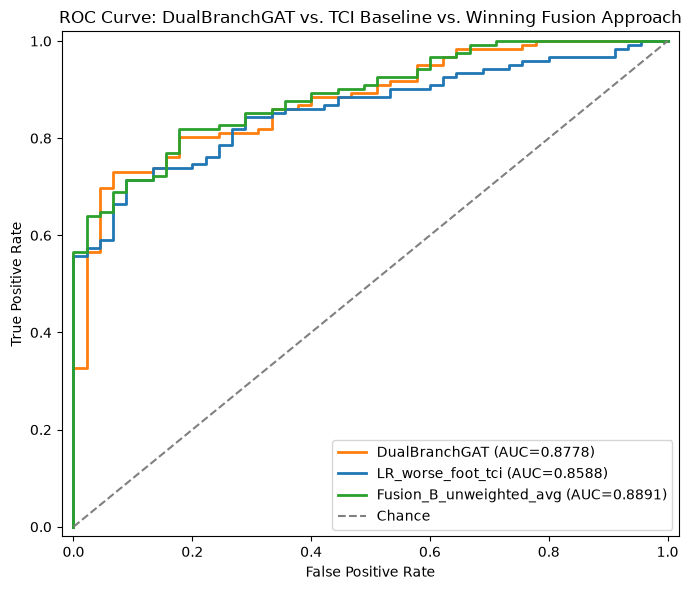

Saved: results\fusion_comparison_roc.png


In [10]:
print("=== SECTION 9: ROC Curve Overlay ===")

fig, ax = plt.subplots(figsize=(7, 6))

curve_specs = [
    ("DualBranchGAT", fusion_df["gat_prob"].values, "#ff7f0e"),
    ("LR_worse_foot_tci", fusion_df["baseline_prob"].values, "#1f77b4"),
    (winning_model_name, winning_probs, "#2ca02c"),
]

for name, probs, color in curve_specs:
    fpr, tpr, _ = roc_curve(y_true, probs)
    auc_val = roc_auc_score(y_true, probs)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.4f})", color=color, linewidth=2)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve: DualBranchGAT vs. TCI Baseline vs. Winning Fusion Approach")
ax.legend(loc="lower right")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
plt.tight_layout()

fig_path = RESULTS_DIR / "fusion_comparison_roc.png"
plt.savefig(fig_path, dpi=150)
plt.show()

print(f"Saved: {fig_path}")


## Section 10 — Qualitative Summary (fill in after running)

*Fill this in from the actual printed numbers above (Sections 6–8) once
this notebook has been run. Do not round up or overstate significance —
report exact p-values.*

- **Winning fusion approach:** `[Fusion_A_weighted_avg / Fusion_B_unweighted_avg / Fusion_C_stacked_LR]`
- **Winning approach's pooled AUC:** `[value]`
- **vs. DualBranchGAT alone** (AUC `[value]`): AUC diff `[value]`, DeLong
  p = `[exact value]` — **`[significant at alpha=0.05 / not significant]`**
- **vs. LR_worse_foot_tci alone** (AUC `[value]`): AUC diff `[value]`,
  DeLong p = `[exact value]` — **`[significant at alpha=0.05 / not significant]`**
- **Error-overlap retention:** of Phase 15's 19 `GAT_ONLY_CORRECT` subjects,
  `[N]` were retained as correct by the winning fusion model; of the 11
  `BASELINE_ONLY_CORRECT` subjects, `[N]` were retained.
- **Overall take:** `[does the fusion model meaningfully close the gap
  between DualBranchGAT and the TCI baseline, and does it reach the
  statistical significance that the individual Phase 14 comparison did
  not?]`


## Section 11 — Save Results

Three output files:

- `results/fusion_comparison.csv` — the Section 6 comparison table.
- `results/fusion_pooled_predictions.csv` — 167 rows: `subject_id`,
  `group`, `true_label`, `fold`, `gat_prob`, `baseline_prob`,
  `fusion_a_prob`, `fusion_b_prob`, `fusion_c_prob`.
- `results/fusion_delong_results.json` — all 6 DeLong comparisons from
  Section 7.


In [11]:
print("=== SECTION 11: Save Results ===")

comparison_path = RESULTS_DIR / "fusion_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)
print(f"Saved: {comparison_path}  shape={comparison_df.shape}")

pooled_cols = [
    "subject_id", "group", "true_label", "fold",
    "gat_prob", "baseline_prob", "fusion_a_prob", "fusion_b_prob", "fusion_c_prob",
]
pooled_path = RESULTS_DIR / "fusion_pooled_predictions.csv"
fusion_df[pooled_cols].to_csv(pooled_path, index=False)
print(f"Saved: {pooled_path}  shape={fusion_df[pooled_cols].shape}")

def _to_jsonable(d):
    return {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in d.items()}

delong_json = {k: _to_jsonable(v) for k, v in delong_results.items()}
delong_path = RESULTS_DIR / "fusion_delong_results.json"
with open(delong_path, "w") as f:
    json.dump(delong_json, f, indent=2)
print(f"Saved: {delong_path}  ({len(delong_json)} comparisons)")


=== SECTION 11: Save Results ===
Saved: results\fusion_comparison.csv  shape=(5, 6)
Saved: results\fusion_pooled_predictions.csv  shape=(167, 9)
Saved: results\fusion_delong_results.json  (6 comparisons)


## Section 12 — Final Summary

Headline sentence for the paper, plus a list of any issues found across the
notebook.


In [12]:
print("=== SECTION 12: FINAL SUMMARY ===")

winning_row = comparison_df[comparison_df["model"] == winning_model_name].iloc[0]
gat_row = comparison_df[comparison_df["model"] == "DualBranchGAT"].iloc[0]
baseline_row = comparison_df[comparison_df["model"] == "LR_worse_foot_tci"].iloc[0]

vs_gat_key = f"{winning_model_name}_vs_DualBranchGAT"
vs_baseline_key = f"{winning_model_name}_vs_LR_worse_foot_tci"
vs_gat = delong_results[vs_gat_key]
vs_baseline = delong_results[vs_baseline_key]

print(f"Winning fusion approach: {winning_model_name}")
print(f"  Pooled AUC:                    {winning_row['roc_auc']:.4f}")
print(f"  DualBranchGAT alone AUC:       {gat_row['roc_auc']:.4f}  (diff {winning_row['roc_auc'] - gat_row['roc_auc']:+.4f}, DeLong p = {vs_gat['p_value']:.4f})")
print(f"  LR_worse_foot_tci alone AUC:   {baseline_row['roc_auc']:.4f}  (diff {winning_row['roc_auc'] - baseline_row['roc_auc']:+.4f}, DeLong p = {vs_baseline['p_value']:.4f})")

print()
headline = (
    f"HEADLINE: The {winning_model_name} fusion of DualBranchGAT and LR_worse_foot_tci "
    f"achieved a pooled AUC of {winning_row['roc_auc']:.4f} vs. {gat_row['roc_auc']:.4f} for "
    f"DualBranchGAT alone (DeLong p = {vs_gat['p_value']:.4f}) and {baseline_row['roc_auc']:.4f} "
    f"for LR_worse_foot_tci alone (DeLong p = {vs_baseline['p_value']:.4f})."
)
print(headline)

print()
if issues_found:
    print(f"Issues found ({len(issues_found)}):")
    for i, issue in enumerate(issues_found, 1):
        print(f"  {i}. {issue}")
else:
    print("0 issues found")


=== SECTION 12: FINAL SUMMARY ===
Winning fusion approach: Fusion_B_unweighted_avg
  Pooled AUC:                    0.8891
  DualBranchGAT alone AUC:       0.8778  (diff +0.0113, DeLong p = 0.3953)
  LR_worse_foot_tci alone AUC:   0.8588  (diff +0.0302, DeLong p = 0.0329)

HEADLINE: The Fusion_B_unweighted_avg fusion of DualBranchGAT and LR_worse_foot_tci achieved a pooled AUC of 0.8891 vs. 0.8778 for DualBranchGAT alone (DeLong p = 0.3953) and 0.8588 for LR_worse_foot_tci alone (DeLong p = 0.0329).

0 issues found
